In [1]:
import pandas as pd
import numpy as np

In [2]:
import warnings

warnings.filterwarnings(action="ignore")

In [3]:
from causaldata import nhefs

data = nhefs.load_pandas().data
data.head(5)

,seqn,qsmk,death,yrdth,modth,dadth,sbp,dbp,sex,age,...,hightax82,price71,price82,tax71,tax82,price71_82,tax71_82,id,censored,older
0,233.0,0.0,0.0,NaN,NaN,NaN,175.0,96.0,0,42.0,...,0.0,2.183594,1.739990,1.102295,0.461975,0.443787,0.640381,1,0.0,0.0
1,235.0,0.0,0.0,NaN,NaN,NaN,123.0,80.0,0,36.0,...,0.0,2.346680,1.797363,1.364990,0.571899,0.549316,0.792969,2,0.0,0.0
2,244.0,0.0,0.0,NaN,NaN,NaN,115.0,75.0,1,56.0,...,0.0,1.569580,1.513428,0.551270,0.230988,0.056198,0.320251,3,0.0,1.0
3,245.0,0.0,1.0,85.0,2.0,14.0,148.0,78.0,0,68.0,...,0.0,1.506592,1.451904,0.524902,0.219971,0.054794,0.304993,4,0.0,1.0
4,252.0,0.0,0.0,NaN,NaN,NaN,118.0,77.0,0,40.0,...,0.0,2.346680,1.797363,1.364990,0.571899,0.549316,0.792969,5,0.0,0.0


In [4]:
data.columns

Index(['seqn', 'qsmk', 'death', 'yrdth', 'modth', 'dadth', 'sbp', 'dbp', 'sex',
       'age', 'race', 'income', 'marital', 'school', 'education', 'ht', 'wt71',
       'wt82', 'wt82_71', 'birthplace', 'smokeintensity', 'smkintensity82_71',
       'smokeyrs', 'asthma', 'bronch', 'tb', 'hf', 'hbp', 'pepticulcer',
       'colitis', 'hepatitis', 'chroniccough', 'hayfever', 'diabetes', 'polio',
       'tumor', 'nervousbreak', 'alcoholpy', 'alcoholfreq', 'alcoholtype',
       'alcoholhowmuch', 'pica', 'headache', 'otherpain', 'weakheart',
       'allergies', 'nerves', 'lackpep', 'hbpmed', 'boweltrouble', 'wtloss',
       'infection', 'active', 'exercise', 'birthcontrol', 'pregnancies',
       'cholesterol', 'hightax82', 'price71', 'price82', 'tax71', 'tax82',
       'price71_82', 'tax71_82', 'id', 'censored', 'older'],
      dtype='str')

In [5]:
from dowhy import CausalModel
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

In [6]:
treatment = "qsmk"         # 1 = quit smoking, 0 = did not quit
outcome = "wt82_71"        # Weight change in kg (1982 minus 1971)

# Baseline patient characteristics that affect both quitting and weight gain
confounders = [
    "sex", "age", "race", "education", 
    "smokeintensity", "smokeyrs", "exercise", "active", "wt71"
]

# define effect modifiers (features along which the treatment effect may vary)
effect_modifiers = ["age", "wt71", "smokeintensity", "smokeyrs"]

stress_test_treatment_strengths = [0.01, 0.05, 0.1]
stress_test_outcome_strengths = [0.5, 1.0, 2.0]

In [7]:
df = data[[treatment, outcome] + confounders].dropna()
print(f"Dataset shape: {df.shape}")

Dataset shape: (1566, 11)


In [8]:
# Create a CausalModel object specifying the graph structure
model = CausalModel(
    data=df,
    treatment=treatment,
    outcome=outcome,
    common_causes=confounders
)
# Identify the causal estimand based on the DAG
identified_estimand = model.identify_effect(proceed_when_unidentifiable=True)
print(f"Identified estimand: {identified_estimand}")


Identified estimand: Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
   d                                                                           ↪
───────(E[wt_82_71|education,wt71,smokeyrs,exercise,race,age,active,sex,smokei ↪
d[qsmk]                                                                        ↪

↪           
↪ ntensity])
↪           
Estimand assumption 1, Unconfoundedness: If U→{qsmk} and U→wt82_71 then P(wt82_71|qsmk,education,wt71,smokeyrs,exercise,race,age,active,sex,smokeintensity,U) = P(wt82_71|qsmk,education,wt71,smokeyrs,exercise,race,age,active,sex,smokeintensity)

### Estimand : 2
Estimand name: iv
No such variable(s) found!

### Estimand : 3
Estimand name: frontdoor
No such variable(s) found!

### Estimand : 4
Estimand name: general_adjustment
Estimand expression:
   d                                                                           ↪
───────(E[wt_82_71|education,wt71,smokeyrs,exercise,race

In [9]:
estimate = model.estimate_effect(
    identified_estimand,
    method_name="backdoor.propensity_score_weighting",
    target_units="ate",
    method_params={
        "weighting_scheme": "ips_weight",
        "propensity_score_model": make_pipeline(
            StandardScaler(),
            LogisticRegression(max_iter=1000)
        )
    }
)

In [10]:
print(f"Estimated Causal Effect (ATE): {estimate.value:.2f} kg")

# Compute 95% Confidence Intervals using bootstrapping
ci = estimate.get_confidence_intervals()
print(f"95% Confidence Interval: {ci}")

# save the estimate and confidence intervals to a CSV file
results_df = pd.DataFrame({
    "estimate": [estimate.value],
    "ci_lower": [ci[0]],
    "ci_upper": [ci[1]]
})

display(results_df)

Estimated Causal Effect (ATE): 3.33 kg
95% Confidence Interval: (np.float64(2.319633289015206), np.float64(4.41776035593844))


,estimate,ci_lower,ci_upper
0,3.334964,2.319633,4.41776


# Refute and Stress-Test Findings

In [11]:
# 1. Refute the estimate using a random common cause
refute_random_common_cause = model.refute_estimate(
        identified_estimand,
        estimate,
        method_name="random_common_cause"
    )
print(f"Random Common Cause Refutation: {refute_random_common_cause}")


Random Common Cause Refutation: Refute: Add a random common cause
Estimated effect:3.3349642082708293
New effect:3.3349642082708293
p value:1.0



In [12]:
# 2. Refute the estimate using a placebo treatment
refute_placebo = model.refute_estimate(
        identified_estimand,
        estimate,
        method_name="placebo_treatment_refuter",
        placebo_type="permute"
    )
print(f"Placebo Treatment Refutation: {refute_placebo}")

Placebo Treatment Refutation: Refute: Use a Placebo Treatment
Estimated effect:3.3349642082708293
New effect:0.6345742426756606
p value:0.17999999999999994



In [13]:
import dowhy.causal_refuters
print(dir(dowhy.causal_refuters))

['AddUnobservedCommonCause', 'BootstrapRefuter', 'CausalRefuter', 'DataSubsetRefuter', 'DummyOutcomeRefuter', 'PlaceboTreatmentRefuter', 'RandomCommonCause', '__all__', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__path__', '__spec__', 'add_unobserved_common_cause', 'bootstrap_refuter', 'data_subset_refuter', 'dummy_outcome_refuter', 'evalue_sensitivity_analyzer', 'get_class_object', 'graph_refuter', 'import_module', 'linear_sensitivity_analyzer', 'placebo_treatment_refuter', 'random_common_cause', 'refute_bootstrap', 'refute_data_subset', 'refute_dummy_outcome', 'refute_estimate', 'refute_placebo_treatment', 'refute_random_common_cause', 'sensitivity_e_value', 'sensitivity_simulation', 'string']


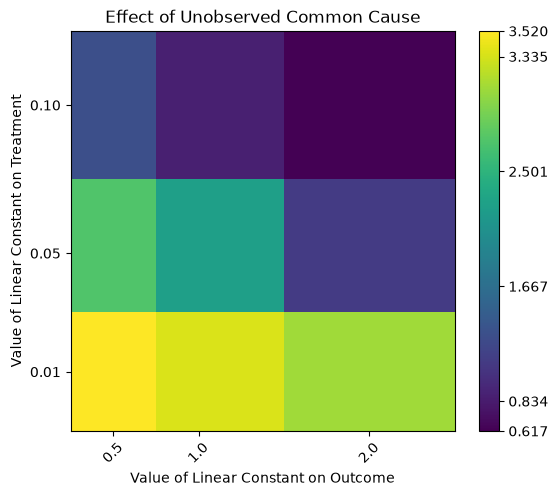

Unobserved Common Cause Refutation: Refute: Add an Unobserved Common Cause
Estimated effect:3.3349642082708293
New effect:(np.float64(0.6173886960609876), np.float64(3.520083154081163))



{'random_common_cause': <dowhy.causal_refuter.CausalRefutation at 0x11a5b12b0>,
 'placebo_treatment': <dowhy.causal_refuter.CausalRefutation at 0x11a648910>,
 'unobserved_common_cause': <dowhy.causal_refuter.CausalRefutation at 0x11a5baa80>}

In [14]:
# stress test the estimate by adding a random confounder
res_unobserved = model.refute_estimate(
        identified_estimand,
        estimate,
        method_name="add_unobserved_common_cause",
        confounders_effect_on_treatment="binary_flip",
        confounders_effect_on_outcome="linear",
        effect_strength_on_treatment=stress_test_treatment_strengths,
        effect_strength_on_outcome=stress_test_outcome_strengths
    )
    
print(f"Unobserved Common Cause Refutation: {res_unobserved}")

    # save the refutation results in a dictionary
refutation_results = {
    "random_common_cause": refute_random_common_cause,
    "placebo_treatment": refute_placebo,
    "unobserved_common_cause": res_unobserved
}

display(refutation_results)

# Double ML

In [15]:
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from econml.dml import LinearDML

In [16]:
estimate_dml = model.estimate_effect(
        identified_estimand,
        method_name="backdoor.econml.dml.LinearDML",
        target_units="ate",
        method_params={
            "init_params": {
                # ML model to predict outcome (continuous weight change)
                "model_y": RandomForestRegressor(n_estimators=100, min_samples_leaf=10, random_state=42),
                # ML model to predict treatment (binary quit smoking)
                "model_t": RandomForestClassifier(n_estimators=100, min_samples_leaf=10, random_state=42),
                "discrete_treatment": True,
                "cv": 5 # Cross-fitting prevents overfitting bias
            },
            "fit_params": {}
        }
    )

print(f"DML Estimated Causal Effect (ATE): {estimate_dml.value:.2f} kg")

display(estimate_dml)


DML Estimated Causal Effect (ATE): 3.44 kg


## Heterogeneous Treatment Effects (CausalForestDML) 

In [17]:
# Re-declare CausalModel specifying effect_modifiers
model_cate = CausalModel(
    data=df,
    treatment=treatment,
    outcome=outcome,
    common_causes=confounders,
    effect_modifiers=effect_modifiers
)
estimand_cate = model_cate.identify_effect(proceed_when_unidentifiable=True)

# 2. Fit CausalForestDML
estimate_cate = model_cate.estimate_effect(
    estimand_cate,
    method_name="backdoor.econml.dml.CausalForestDML",
    target_units="ate",
    method_params={
        "init_params": {
            "model_y": RandomForestRegressor(n_estimators=100, min_samples_leaf=10, random_state=42),
            "model_t": RandomForestClassifier(n_estimators=100, min_samples_leaf=10, random_state=42),
            "discrete_treatment": True,
            "n_estimators": 200,
            "random_state": 42
        },
        "fit_params": {}
    }
)

In [27]:
# 3. Predict individual CATE for each patient in the dataset
# Access the underlying EconML estimator to get personalized predictions and intervals
    
raw_cf = estimate_cate.estimator.estimator
lower_ci, upper_ci = raw_cf.effect_interval(df[effect_modifiers].values, alpha=0.05)

df["predicted_cate"] = raw_cf.effect(df[effect_modifiers].values).ravel()
df["cate_lower_95"] = lower_ci.ravel()
df["cate_upper_95"] = upper_ci.ravel()


#Inspecting subgroups: Comparing weight gain for younger vs. older smokers
df["age_group"] = pd.cut(df["age"], bins=[20, 40, 60, 80], labels=["20-40", "41-60", "61+"])
subgroup_summary = df.groupby("age_group", observed=False)[["predicted_cate", "cate_lower_95", "cate_upper_95"]].mean()

# display results
display(subgroup_summary.round(2))

,predicted_cate,cate_lower_95,cate_upper_95
age_group,,,
20-40,4.34,-0.81,9.48
41-60,4.03,-0.37,8.43
61+,3.30,-0.08,6.67


In [ ]:
# 1. Fit an outcome model E[Y | T, X]
features = [treatment] + confounders
outcome_model = RandomForestRegressor(n_estimators=200, min_samples_leaf=10, random_state=42)
outcome_model.fit(df[features], df[outcome])

# 2. Create two counterfactual datasets for ALL patients
df_all_quit = df[features].copy()
df_all_quit[treatment] = 1  # Counterfactual: Everyone quits smoking

df_all_continue = df[features].copy()
df_all_continue[treatment] = 0  # Counterfactual: Everyone continues smoking

# 3. Predict potential outcomes E[Y(1)] and E[Y(0)]
y1_hat = outcome_model.predict(df_all_quit)
y0_hat = outcome_model.predict(df_all_continue)

# 4. G-computation ATE = Mean(Y(1)) - Mean(Y(0))
gcomp_ate = (y1_hat - y0_hat).mean()

print(f"Expected weight change if everyone quit E[Y(1)]:      {y1_hat.mean():.2f} kg")
print(f"Expected weight change if everyone continued E[Y(0)]: {y0_hat.mean():.2f} kg")
print(f"G-Computation ATE (Difference):                       {gcomp_ate:.2f} kg")


Expected weight change if everyone quit E[Y(1)]:      4.98 kg
Expected weight change if everyone continued E[Y(0)]: 1.83 kg
G-Computation ATE (Difference):                       3.14 kg


## Expand confounders

In [33]:
expanded_confounders = [
    # Original 9 core confounders
    "sex", "age", "race", "education", 
    "smokeintensity", "smokeyrs", "exercise", "active", "wt71",
    
    # Additional 1971 baseline anthropometrics, vitals & lifestyle
    "ht", "marital", "sbp", "dbp", "cholesterol", "alcoholfreq",
    
    # Additional 1971 baseline medical history
    "asthma", "bronch", "hbp", "diabetes", "pepticulcer", "wtloss"
]

df = data[[treatment, outcome] + expanded_confounders].dropna().copy()
print(f"Expanded cohort size: {len(df)} patients with {len(expanded_confounders)} confounders")


Expanded cohort size: 1517 patients with 21 confounders


In [34]:
model = CausalModel(
    data=df,
    treatment=treatment,
    outcome=outcome,
    common_causes=expanded_confounders
)
# Identify the causal estimand based on the DAG
identified_estimand = model.identify_effect(proceed_when_unidentifiable=True)
print(f"Identified estimand: {identified_estimand}")

estimate = model.estimate_effect(
    identified_estimand,
    method_name="backdoor.propensity_score_weighting",
    target_units="ate",
    method_params={
        "weighting_scheme": "ips_weight",
        "propensity_score_model": make_pipeline(
            StandardScaler(),
            LogisticRegression(max_iter=1000)
        )
    }
)

print(f"Estimated Causal Effect (ATE): {estimate} kg")

# Compute 95% Confidence Intervals using bootstrapping
ci = estimate.get_confidence_intervals()
print(f"95% Confidence Interval: {ci}")

# save the estimate and confidence intervals to a CSV file
results_df = pd.DataFrame({
    "estimate": [estimate.value],
    "ci_lower": [ci[0]],
    "ci_upper": [ci[1]]
})

Identified estimand: Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
   d                                                                           ↪
───────(E[wt_82_71|diabetes,education,bronch,wt71,exercise,race,age,ht,sex,cho ↪
d[qsmk]                                                                        ↪

↪                                                                              ↪
↪ lesterol,marital,dbp,hbp,smokeyrs,alcoholfreq,sbp,smokeintensity,asthma,wtlo ↪
↪                                                                              ↪

↪                        
↪ ss,pepticulcer,active])
↪                        
Estimand assumption 1, Unconfoundedness: If U→{qsmk} and U→wt82_71 then P(wt82_71|qsmk,diabetes,education,bronch,wt71,exercise,race,age,ht,sex,cholesterol,marital,dbp,hbp,smokeyrs,alcoholfreq,sbp,smokeintensity,asthma,wtloss,pepticulcer,active,U) = P(wt82_71|qsmk,diabetes,education,bronch,wt71,exercise,

In [35]:
display(results_df)

,estimate,ci_lower,ci_upper
0,3.051706,1.957643,4.124375


In [36]:
refute_placebo = model.refute_estimate(
        identified_estimand,
        estimate,
        method_name="placebo_treatment_refuter",
        placebo_type="permute"
    )
print(f"Placebo Treatment Refutation: {refute_placebo}")

Placebo Treatment Refutation: Refute: Use a Placebo Treatment
Estimated effect:3.0517061435465958
New effect:0.4169569492666473
p value:0.41999999999999993

